check_event  : Everything looks fine...
[2457205.21, 0.309, 10.7821, 1.3, 0.001, 1.9, np.float64(10000.0), np.float64(12000.0)]


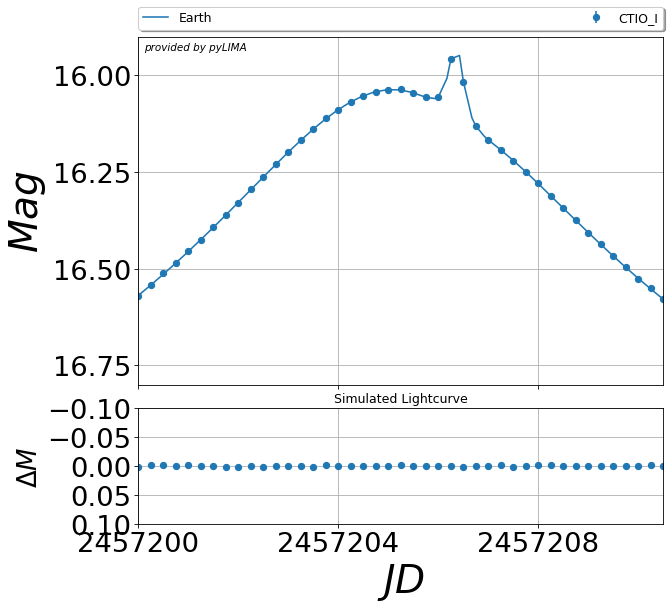

In [1]:
from pyLIMA import event
from pyLIMA.simulations import simulator
from pyLIMA.fits import TRF_fit
from pyLIMA.models import PSBL_model
from pyLIMA.outputs import pyLIMA_plots
import numpy as np
import matplotlib.pyplot as plt

# Create simulated Microlensing event
event_3 = event.Event(ra=270, dec=0)
event_3.name = 'My simulated event'

CTIO_I = simulator.simulate_a_telescope(name='CTIO_I', time_start=2457190, time_end=2457220, sampling=6, 
                                        location='Earth', camera_filter='I',
                                        uniform_sampling=True, astrometry=False)
# LCO_SAAO = simulator.simulate_a_telescope(name='LCO_SAAO', time_start=2457205, time_end=2457208, sampling=1, 
#                                         location='Earth', camera_filter='I',
#                                         uniform_sampling=True, astrometry=False)

event_3.telescopes.append(CTIO_I)
# event_3.telescopes.append(LCO_SAAO)
event_3.check_event()

psbl_sim = PSBL_model.PSBLmodel(event_3)
psbl_sim_params = simulator.simulate_microlensing_model_parameters(psbl_sim)

### Set the parameters to some reasonable values.
psbl_sim_params[0] = 2457205.21 # t0
psbl_sim_params[1:3] = [0.309, 10.7821] # u0, tE
psbl_sim_params[3:6] = [1.3, 0.001, 1.9] # s, q, alpha

### Set the source and blend fluxes of all telescopes to the same values for plotting purposes.
n_tel = len(event_3.telescopes)
psbl_sim_params[-n_tel*2::2] = 10000. * np.ones(n_tel) # source fluxes
psbl_sim_params[-n_tel*2+1::2] = 12000. * np.ones(n_tel) # total fluxes
print(psbl_sim_params)

### Transform the parameters into a pyLIMA class object.
pyLIMA_parameters_1 = psbl_sim.compute_pyLIMA_parameters(psbl_sim_params)

### Inject everthing into the simulator to produce a light curve.
simulator.simulate_lightcurve(psbl_sim, pyLIMA_parameters_1)

pyLIMA_plots.plot_lightcurves(psbl_sim, psbl_sim_params)
plt.title('Simulated Lightcurve')
plt.gcf().axes[0].set_xlim(2457200.0, 2457210.5)
plt.gcf().axes[0].set_ylim(16.8, 15.9)
plt.show()

/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:350: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
  add_cbar=True, norm=colors.LogNorm(1e-5, 1e5), cbar_label='$\\sum\,\\chi^2$',


Selecting CTIO_I to estimate u0, tE and fs
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.25, 0.47461683045013425, 5.5, 18646.993298165187, 14326.436206658502]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.1942979973)),
             ('u0', np.float64(0.3113514063076104)),
             ('tE', np.float64(10.824923241719786)),
             ('fsource_CTIO_I', np.float64(9963.889764636993)),
             ('ftotal_CTIO_I', np.float64(11988.256590560497)),
             ('soft_l1', np.float64(708.415658455005))])


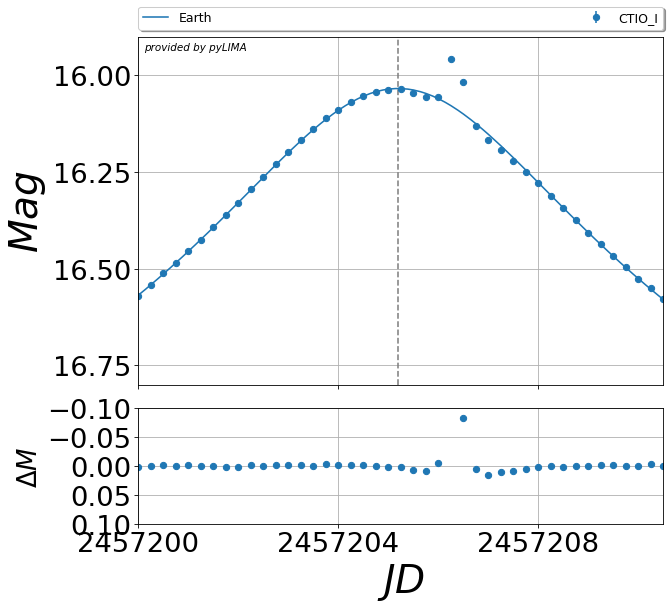

In [2]:
from planet_anomaly_map import PlanetAnomalyMap

anomaly = PlanetAnomalyMap(event=event_3, 
                       window_limits=((2457200.0, 2457210.5),(16.8, 15.9)))

anomaly.run_pspl_fit()
fig_pspl = anomaly.plot_pspl_model(show=True)


Planet Anomaly Map done.


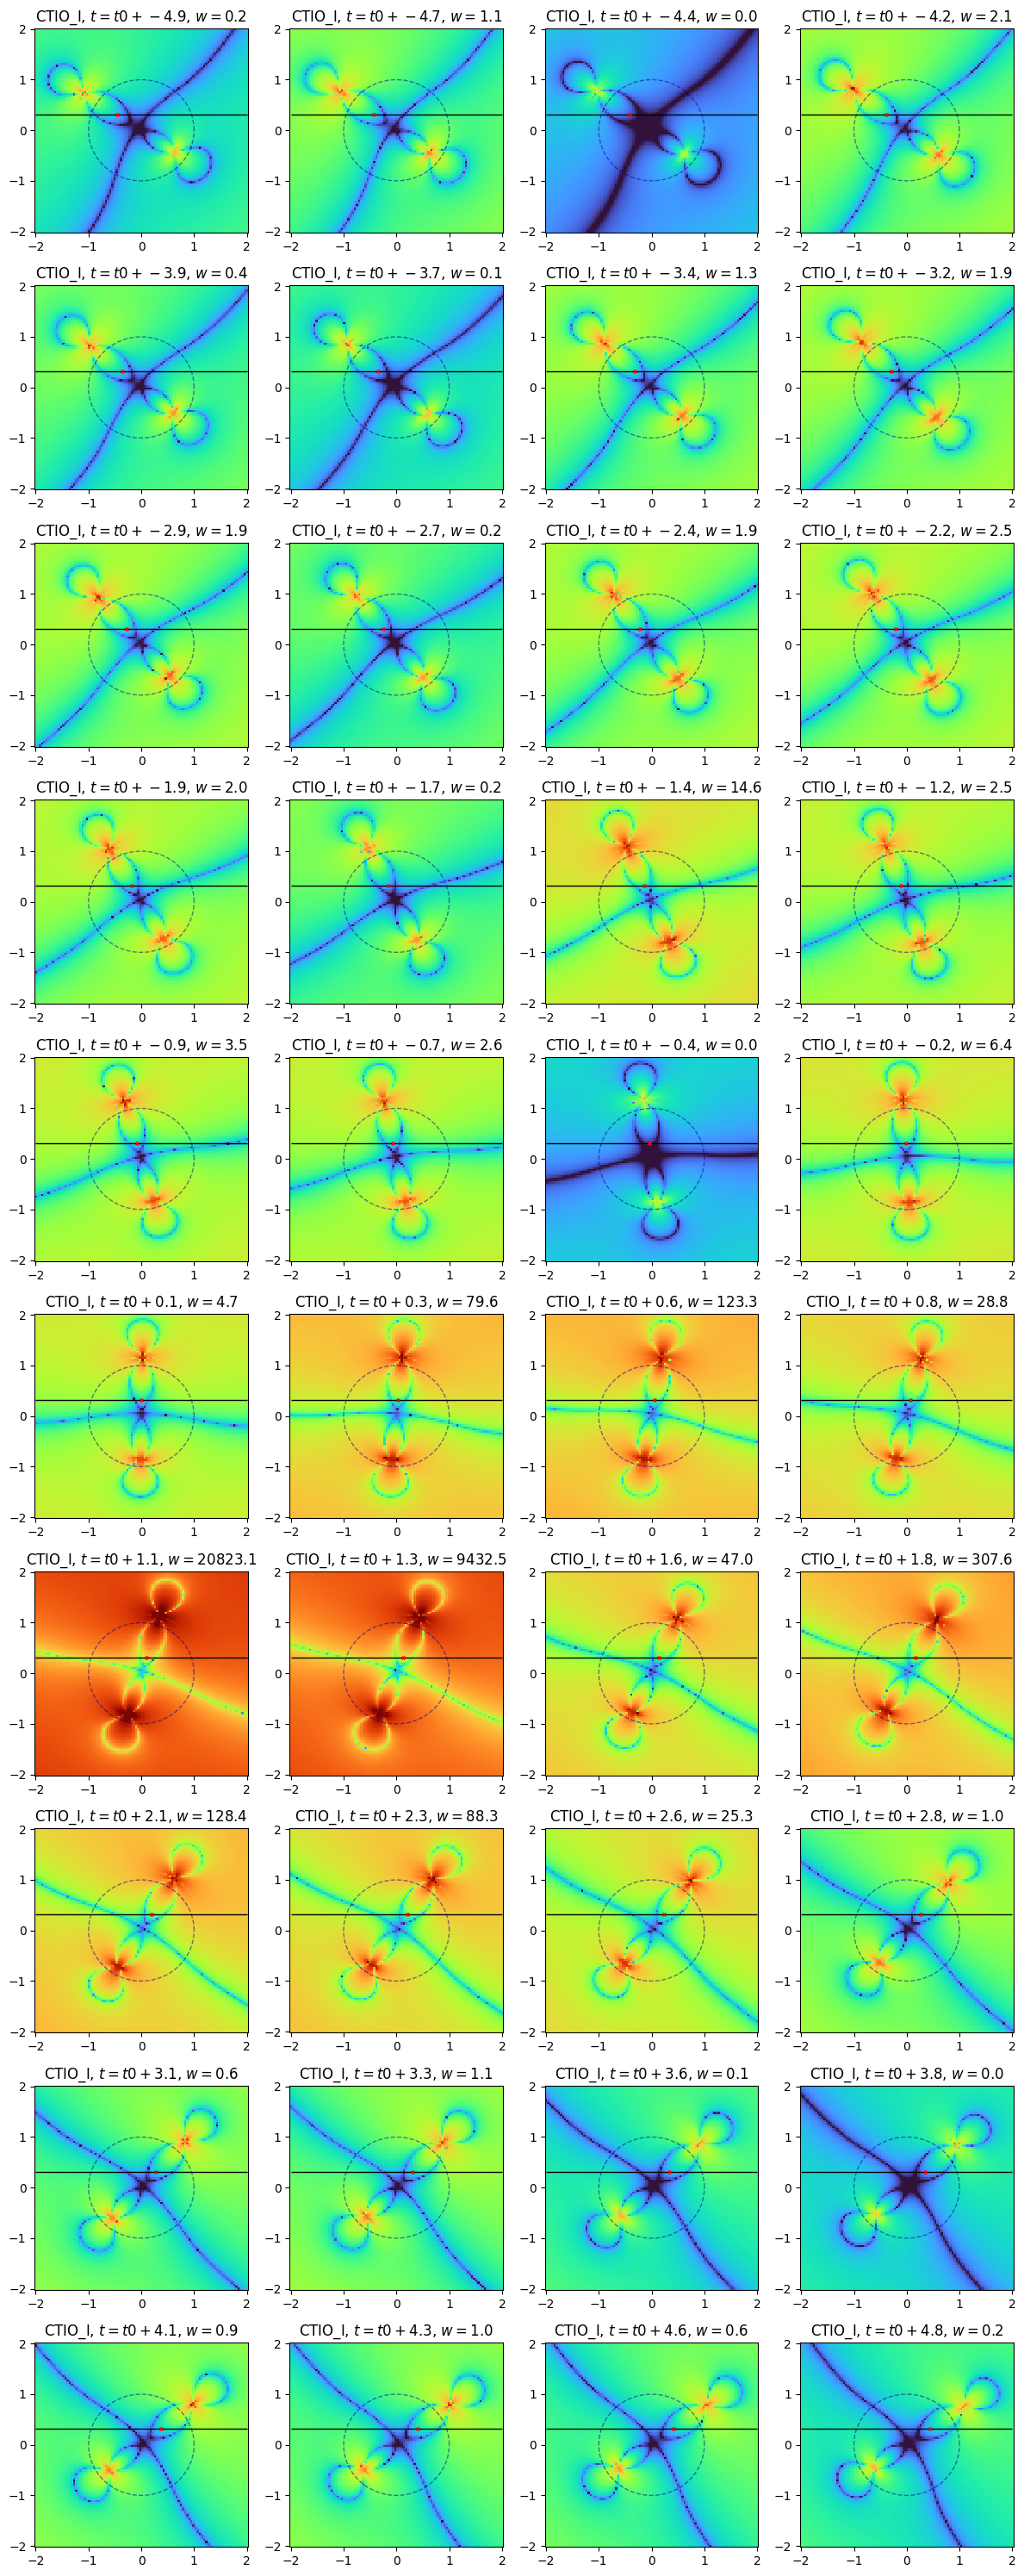

<Figure size 640x480 with 0 Axes>

In [3]:
anomaly.create_planet_anomaly_map(
    meshgrid_corners=((-2.0,2.0),(-2.0,2.0)), 
    resolution=100)
fig_overview = anomaly.plot_overview(show=True)


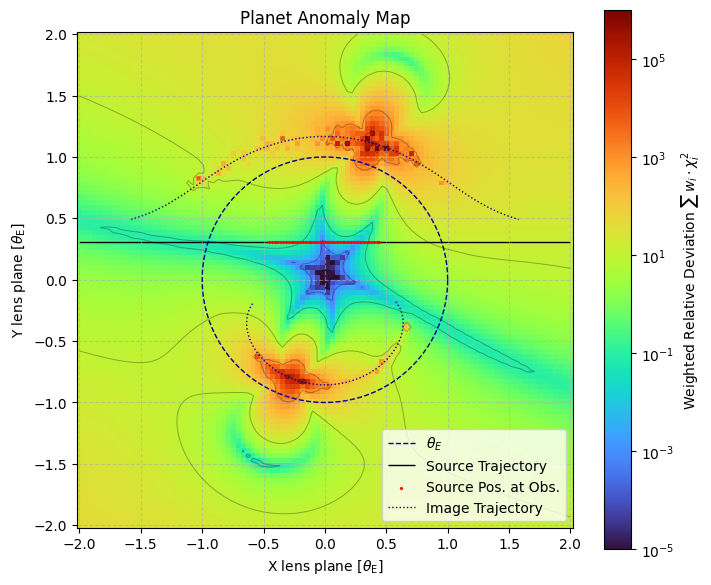

<Figure size 640x480 with 0 Axes>

In [4]:
fig_pam = anomaly.plot_planet_anomaly_map(show=True)
meshgrid, pam = anomaly.get_planet_anomaly_map()

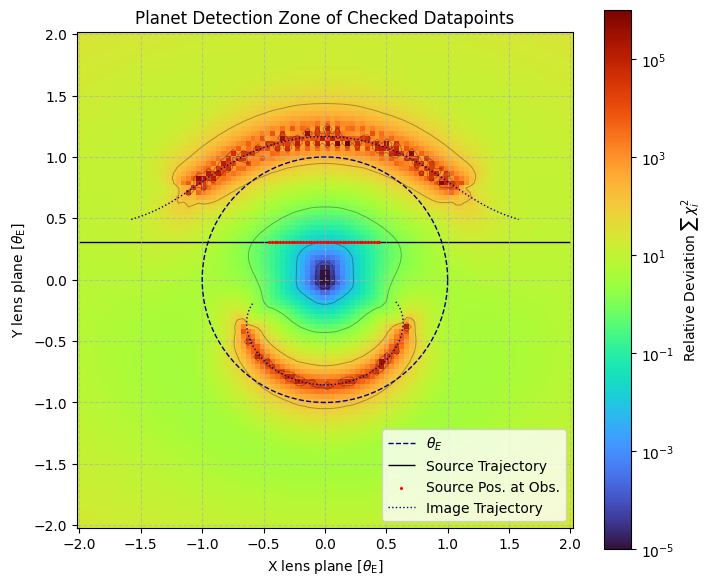

<Figure size 640x480 with 0 Axes>

In [5]:
fig_pdzm = anomaly.plot_planet_detection_zone_map(show=True)
meshgrid, pam = anomaly.get_planet_anomaly_map()

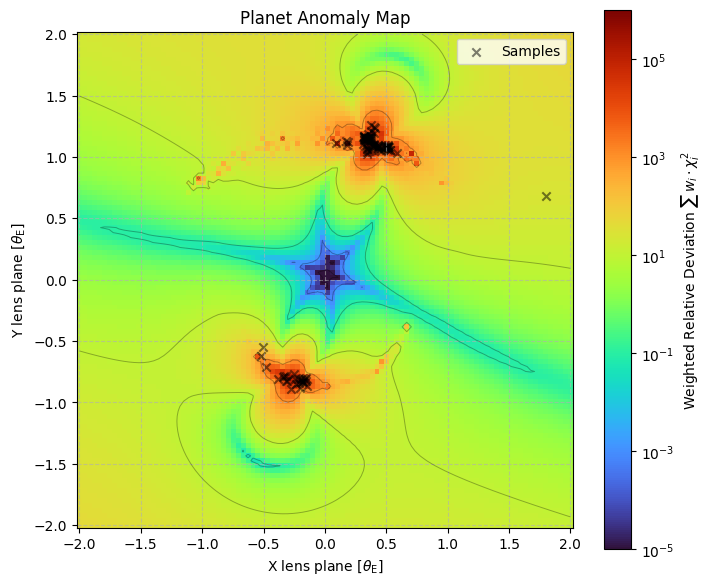

/home/jakob/projects/pyLIMA-docs-revisit/my_project/planet_anomaly_map/planet_anomaly_map.py:362: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  contour = plt.pcolormesh(X, Y, Z,


<Figure size 640x480 with 0 Axes>

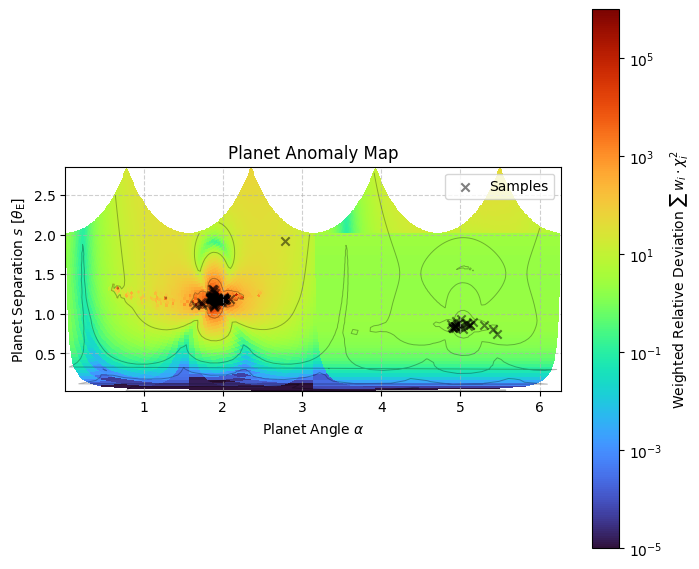

<Figure size 640x480 with 0 Axes>

In [6]:
x_y_samples = anomaly.sample_from_planet_anomaly_map(n_samples=100)
fig_samples_xy = anomaly.create_sample_overview_plot(show=True, s_alpha_plot=False)
s_alpha_samples = anomaly.convert_x_y_to_s_alpha_samples()
fig_samples_salpha = anomaly.create_sample_overview_plot(show=True, s_alpha_plot=True)

In [7]:
### Run TRF Fits with these Initial Values

# use pspl params
t0 = anomaly.t0
u0 = anomaly.u0
te = anomaly.tE

# unpack s and alpha samples
s_samples = s_alpha_samples[:,0]
alpha_samples = s_alpha_samples[:,1]

# best fit object
best_fit = None

for i, (s, alpha) in enumerate(zip(s_samples, alpha_samples)):
    # create PSBL model
    psbl = PSBL_model.PSBLmodel(event_3)
    
    # create fit, set initial parameters, fit
    fit = TRF_fit.TRFfit(psbl, loss_function='chi2')
    fit.model_parameters_guess = [t0, u0, te, s, 0.001, alpha]
    fit.fit()

    # check chi2
    try:
        if best_fit == None or fit.fit_results[fit.loss_function] < best_fit.fit_results[best_fit.loss_function]:
            best_fit = fit
    except:
        print(f'Fit {i} failed: s={s}, alpha={alpha}\n')


initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.1942979973, 0.3113514063076104, 10.824923241719786, 0.8437032642299608, 0.001, 4.926448071174349, 9337.239320013145, 12407.163808839787]
Trust Region Reflective fit SUCCESS
best model:
OrderedDict([('t0', np.float64(2457205.2196066966)),
             ('u0', np.float64(0.25939100617326244)),
             ('tE', np.float64(12.285211893746718)),
             ('separation', np.float64(0.7805600725151325)),
             ('mass_ratio', np.float64(0.00033199072363139536)),
             ('alpha', np.float64(4.833542797527822)),
             ('fsource_CTIO_I', np.float64(8065.83197800308)),
             ('ftotal_CTIO_I', np.float64(11808.412431295877)),
             ('chi2', np.float64(26481.327867187083))])
initial_guess  : Initial parameters guess SUCCESS
Using guess:  [2457205.1942979973, 0.3113514063076104, 10.824923241719786, 1.2051400365237896, 0.001, 1.8657109089834363, 8533.148709206836, 12910.680770828283]
Trust R

Best fit choosen with a chi^2 of 98.74379713584607 and parameters:
OrderedDict([('t0', np.float64(2457205.211332438)),
             ('u0', np.float64(0.3054293211374714)),
             ('tE', np.float64(10.882032702928937)),
             ('separation', np.float64(1.29597737309236)),
             ('mass_ratio', np.float64(0.0009689096189363728)),
             ('alpha', np.float64(1.9004691850820004)),
             ('fsource_CTIO_I', np.float64(9857.950749565867)),
             ('ftotal_CTIO_I', np.float64(11984.721461612793)),
             ('chi2', np.float64(98.74379713584607))])


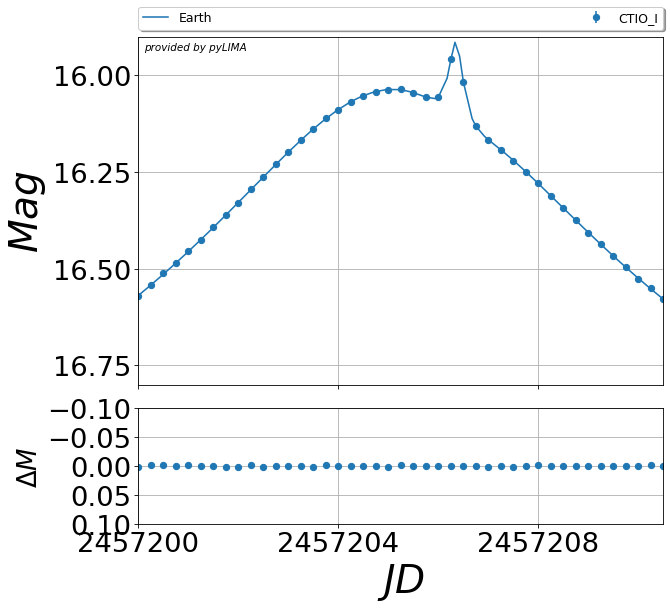

In [8]:
### Give overview over best fit
import pprint
from collections import OrderedDict 

# extract params
best_psbl_params =  OrderedDict(zip(best_fit.priors_parameters.keys(), best_fit.fit_results['best_model']))
best_psbl_params[best_fit.loss_function] = best_fit.fit_results[best_fit.loss_function]

print(f'Best fit choosen with a chi^2 of {best_fit.fit_results['chi2']} and parameters:')
pprint.pprint(best_psbl_params)

# plot
fig, _ = pyLIMA_plots.plot_lightcurves(psbl, best_fit.fit_results['best_model'])
fig.axes[0].set_xlim(2457200.0, 2457210.5)
fig.axes[0].set_ylim(16.8, 15.9)
plt.show()